# Information-Theoretic Signatures of Human and AI-Generated Software

## Aim and research questions

AI-generated contributions complicate code review and can make the experience of software development painful.
AI-DDOS attacks on open source repositories have led projects to outright ban outside contribution and it has brought into the discussion of ownership and responsiblity.
Being able to recognize ai-generated code is of utmost importance in this context.

Using matched [SWE-bench](https://arxiv.org/abs/2310.06770) Python fixes, this study asks whether AI-generated and human-written code differ in three interpretable information-theoretic properties:

1. **Shannon entropy:** diversity of syntactic tokens.
2. **Mutual information (MI):** dependence between tokens at increasing distances.
3. **Active information storage (AIS):** predictability of a token from its preceding history.

The AI submissions are Claude Opus 4.5, Gemini 3 Flash and GPT-5.2-Codex. Matching by software issue reduces task-level differences but does not isolate model effects from agent configuration or selection. All comparisons are **AI minus human**, measured in **bits**.

Our hypothesis are:

**H1**: AI-generated patches will differ from human patches in token entropy.

**H2**: AI-generated patches will exhibit greater short-range sequential dependence and
predictability than matched human patches, reflected in higher short-range MI and AIS



## 1. Data import and processing

**Data.** SWE-bench Verified tasks are matched by `instance_id` against human gold patches and saved AI submissions. Each solution is reconstructed from the same base revision.

| Model | Submission ID |
|---|---|
| Claude Opus 4.5 | `20260217_mini-v2.0.0_claude-4-5-opus-high` |
| Gemini 3 Flash | `20260217_mini-v2.0.0_gemini-3-flash-high` |
| GPT-5.2-Codex | `20260219_mini-v2.0.0_gpt-5-2-codex` |

**Selection.** Retain matched Python implementation files, excluding tests, vendored files and unmatched or unreconstructable changes. Retained cohorts are *not* limited to resolved tasks. Results therefore describe selected, reconstructable changes—not all SWE-bench submissions. The same human task can appear in multiple model comparisons.

**Encoding.** The hybrid syntax tokenizer maps non-keyword identifiers to `IDENT`, numerals to `NUMBER`, and strings to `STRING`; keywords, operators, indentation and logical newlines remain distinct. Comments and non-logical newlines are excluded. This controls spelling variation but does not remove vocabulary or style differences.

**Sequence definition.** Entropy and MI use ordered tokens from added/replaced Python lines (no deleted or unchanged tokens). MI respects file boundaries but may connect additions separated by omitted unchanged lines. AIS instead samples **contiguous added-code blocks**, never crossing unchanged gaps. Whole-file entropy is a separate contextual check.

| Eligible matched tasks | Claude | Gemini | Codex |
|---|---:|---:|---:|
| Added-code entropy | 362 | 386 | 391 |
| MI, lags 1–20 | 239 | 254 | 260 |
| MI, lags 21–40 | 109 | 128 | 128 |
| MI, lags 41–60 | 75 | 81 | 83 |
| MI, complete lags 1–100 | 36 | 41 | 43 |
| Primary AIS, 50-token windows | 57 | 54 | 66 |

**Unit of inference:** matched *tasks*, not files, token pairs or overlapping windows. Eligibility changes by measure and lag range, so the cohorts are not directly interchangeable.

In [51]:
import json
from pathlib import Path

import numpy as np
import pandas as pd

# All project inputs are contained in data/. Run from the notebook directory.
DATA_ROOT = Path("data/swe_bench_models")
JIDT_JAR = Path("data/jidt/infodynamics.jar")

MODELS = {
    "claude": {
        "id": "claude_opus_4_5",
        "display": "Claude",
        "submission": "20260217_mini-v2.0.0_claude-4-5-opus-high"
    },
    "gemini": {
        "id": "gemini_3_flash",
        "display": "Gemini",
        "submission": "20260217_mini-v2.0.0_gemini-3-flash-high"
    },
    "codex": {
        "id": "gpt_5_2_codex",
        "display": "Codex",
        "submission": "20260219_mini-v2.0.0_gpt-5-2-codex"
    }
}

# Verify raw inputs; eligibility is derived in the analysis cells.
data_rows = []
for model in MODELS.values():
    directory = DATA_ROOT / model['id']
    for name in ('selection.json', 'file_audit.json', 'sequences.json', 'work', 'patches'):
        if not (directory / name).exists():
            raise FileNotFoundError(directory / name)
    selected = json.loads((directory / 'selection.json').read_text())
    data_rows.append({'Model': model['display'], 'Selected tasks': len(selected)})
if not JIDT_JAR.is_file():
    raise FileNotFoundError(JIDT_JAR)
pd.DataFrame(data_rows)


,Model,Selected tasks
0,Claude,500
1,Gemini,500
2,Codex,500


## 2. Shannon entropy

Shannon entropy measures uncertainty in a token drawn from the empirical token distribution:

$$
\widehat{H}(X)=-\sum_{x:\widehat{p}(x)>0}\widehat{p}(x)\log_2\widehat{p}(x),
\qquad \widehat{p}(x)=\frac{n_x}{n}.
$$

Higher entropy indicates greater **token-frequency diversity**, not necessarily more complex or better code. Entropy ignores order: shuffling tokens without changing counts leaves it unchanged. Under a uniform distribution over $V$ observed token types, $H=\log_2 V$.

The principal measure is **added-code entropy**, calculated per retained file. **Whole-file entropy** provides context but can dilute patch differences with shared unchanged code. Both use the hybrid encoding and empirical discrete entropy (JIDT); short sequences and vocabulary size can bias estimates.

### Setup and Dependencies

Initialize JIDT and import necessary libraries for data processing and information-theoretic calculations.

In [52]:
import hashlib
import io
import keyword
import token
import tokenize
from pathlib import Path

import jpype
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from unidiff import PatchSet

if not jpype.isJVMStarted():
    jpype.startJVM(classpath=[str(JIDT_JAR.resolve())])
EntropyCalculatorDiscrete = jpype.JClass('infodynamics.measures.discrete.EntropyCalculatorDiscrete')

ENTROPY_TIE_TOLERANCE = 1e-12

def verified_text(path, expected_hash):
    content = path.read_bytes()
    if hashlib.sha256(content).hexdigest() != expected_hash:
        raise ValueError(f"Input hash mismatch: {path}")
    return content.decode('utf-8')


### Encoding

Define the hybrid syntax tokenizer. This mapping simplifies the token space by grouping identifiers, numbers, and strings while preserving Python keywords and structural tokens (operators, indentation, newlines).

In [53]:
def _lex(source: str) -> list[tokenize.TokenInfo]:
    ignored = {
        token.ENDMARKER,
        tokenize.ENCODING,
        tokenize.COMMENT,
        tokenize.NL,
    }

    return [
        tok
        for tok in tokenize.generate_tokens(
            io.StringIO(source).readline
        )
        if tok.type not in ignored
    ]

def encode_hybrid(source: str) -> list[str]:
    result = []

    for tok in _lex(source):
        if tok.type == token.NAME:
            if keyword.iskeyword(tok.string):
                result.append(tok.string)
            else:
                result.append("IDENT")

        elif tok.type == token.NUMBER:
            result.append("NUMBER")

        elif tok.type == token.STRING:
            result.append("STRING")

        elif tok.type == token.OP:
            result.append(tok.string)

        else:
            result.append(token.tok_name[tok.type])

    return result


### Changed lines

Identify which lines were added in a given patch file using `unidiff`.

In [54]:
def changed_lines(file_patch):
    """Read added-line positions supplied by unidiff."""
    return {line.target_line_no for hunk in file_patch for line in hunk if line.is_added}


### Added tokens

Filter the tokenized source code to retain only those tokens that appear on lines added or modified in the patch.

In [55]:
def added_tokens(source, added_lines):
    tokens = []
    lexical_tokens = _lex(source)
    hybrid_tokens = encode_hybrid(source)

    for lexical, encoded in zip(lexical_tokens, hybrid_tokens, strict=True):
        # DEDENT marks a boundary and has no source text of its own.
        if lexical.type == token.DEDENT:
            continue

        start_line, _ = lexical.start
        end_line, end_column = lexical.end
        if end_column == 0:
            end_line -= 1  # The end position is exclusive.

        token_lines = range(start_line, end_line + 1)
        if added_lines.intersection(token_lines):
            tokens.append(encoded)

    return tokens


### Entropy calculation

Calculate the Shannon entropy of a token sequence using JIDT's `EntropyCalculatorDiscrete`.

In [56]:
def token_entropy(tokens):
    if not tokens:
        raise ValueError("Cannot calculate entropy of an empty sequence")
    vocabulary = {symbol: i for i, symbol in enumerate(sorted(set(tokens)))}
    if len(vocabulary) == 1:
        return 0.0
    calculator = EntropyCalculatorDiscrete(len(vocabulary))
    calculator.initialise()
    calculator.addObservations(jpype.JArray(jpype.JInt)([vocabulary[t] for t in tokens]))
    return float(calculator.computeAverageLocalOfObservations())


### Data Loading

Define helpers to load model metadata and group file audit records.

In [57]:
def load_model_metadata(directory):
    tasks = {r['instance_id']: r for r in json.loads((directory / 'selection.json').read_text())}
    audit = json.loads((directory / 'file_audit.json').read_text())
    hashes = {(r['instance_id'], r['source']): r['patch_sha256']
              for r in json.loads((directory / 'sequences.json').read_text())}
    return tasks, audit, hashes

def group_audit_by_file(audit):
    files = {}
    for row in audit:
        if row['status'] == 'ok':
            files.setdefault((row['instance_id'], row['file_id'], row['path']), {})[row['source']] = row
    return files


### Processing

Define a helper to process a matched file pair, verifying sources and patches, and extracting token sequences.

In [58]:
def process_file_pair(model_dir, instance, file_id, path, pair_audit, hashes, patches):
    sources, sequences = {}, {}
    for author in ('ai', 'human'):
        record = pair_audit[author]
        source_path = model_dir / 'work' / instance / author / file_id / path
        source = verified_text(source_path, record['result_sha256'])
        
        patch_key = (instance, author)
        if patch_key not in patches:
            patch_path = model_dir / 'patches' / instance / f'{author}.patch'
            patch_text = verified_text(patch_path, hashes[patch_key])
            patches[patch_key] = {file.path: file for file in PatchSet(patch_text)}
        
        lines = changed_lines(patches[patch_key][path])
        sources[author] = source
        sequences[author] = {'added': added_tokens(source, lines), 'whole': encode_hybrid(source)}
        
    if sources['ai'] == sources['human']:
        return None, 'identical_sources'
    if any(not sequences[a]['added'] for a in ('ai', 'human')):
        return None, 'no_added_tokens'
        
    return sequences, None


### Execution

Iterate through the models and tasks, computing entropy for both added code and the entire file.

In [59]:
entropy_records, entropy_skipped = [], []

for model in MODELS.values():
    model_id = model['id']
    directory = DATA_ROOT / model_id
    
    tasks, audit, hashes = load_model_metadata(directory)
    files = group_audit_by_file(audit)
    patches = {}
    
    for (instance, file_id, path), pair_audit in sorted(files.items()):
        identity = {'model': model_id, 'instance_id': instance, 'repo': tasks[instance]['repo'], 'path': path}
        
        if set(pair_audit) != {'ai', 'human'}:
            entropy_skipped.append({**identity, 'reason': 'unmatched_file'})
            continue

        sequences, skip_reason = process_file_pair(directory, instance, file_id, path, pair_audit, hashes, patches)
        
        if skip_reason:
            entropy_skipped.append({**identity, 'reason': skip_reason})
            continue
            
        for mode in ('added', 'whole'):
            entropy_records.append({
                **identity, 'mode': mode,
                'ai_bits': token_entropy(sequences['ai'][mode]),
                'human_bits': token_entropy(sequences['human'][mode]),
                'ai_tokens': len(sequences['ai'][mode]),
                'human_tokens': len(sequences['human'][mode])
            })
            
    print(f"{model['display']}: JIDT entropy calculation complete.")

entropy_files = pd.DataFrame(entropy_records)
entropy_skipped = pd.DataFrame(entropy_skipped)


Claude: JIDT entropy calculation complete.
Gemini: JIDT entropy calculation complete.
Codex: JIDT entropy calculation complete.


### Aggregation logic

Define functions to validate and aggregate entropy results at the task and model levels.

In [60]:
def validate_entropy_results(df):
    # Keep paired, finite measurements so both sources use identical files.
    valid = np.isfinite(df[['ai_bits', 'human_bits']]).all(axis=1)
    df = df.loc[valid].copy()

    file_keys = ['model', 'instance_id', 'path']
    if df.duplicated(file_keys + ['mode']).any():
        raise ValueError("Duplicate per-file entropy measurements")

    added_files = pd.MultiIndex.from_frame(df.loc[df['mode'] == 'added', file_keys])
    whole_files = pd.MultiIndex.from_frame(df.loc[df['mode'] == 'whole', file_keys])
    if set(added_files) != set(whole_files):
        raise ValueError("Added-code and whole-file entropy must use the same file pairs")

    return df

def calculate_task_averages(df):
    # Average files within each task, then give each task equal weight.
    # Preserve numeric task-level values for the following inference cell.
    tasks = (
        df.groupby(['model', 'mode', 'instance_id', 'repo'], as_index=False)
        .agg(ai_bits=('ai_bits', 'mean'), human_bits=('human_bits', 'mean'),
             files=('path', 'size'))
    )
    tasks['ai_minus_human_bits'] = tasks['ai_bits'] - tasks['human_bits']
    return tasks

def summarize_by_model(tasks_df, models_config):
    summary = (
        tasks_df.groupby(['mode', 'model'])
        .agg(tasks=('instance_id', 'nunique'), files=('files', 'sum'),
             ai_bits=('ai_bits', 'mean'), human_bits=('human_bits', 'mean'),
             ai_minus_human_bits=('ai_minus_human_bits', 'mean'))
        .reindex(pd.MultiIndex.from_product(
            [['added', 'whole'], [model['id'] for model in models_config.values()]],
            names=['mode', 'model']))
        .reset_index()
    )

    # Mapping for display
    summary['model'] = summary['model'].map(
        {model['id']: model['display'] for model in models_config.values()})
    summary['mode'] = summary['mode'].map({'added': 'Added code', 'whole': 'Whole file'})

    return summary.rename(columns={
        'mode': 'Scope', 'model': 'Model', 'tasks': 'Tasks', 'files': 'File pairs',
        'ai_bits': 'Mean AI entropy (bits/token)', 'human_bits': 'Mean human entropy (bits/token)',
        'ai_minus_human_bits': 'Mean AI − human (bits/token)'})


### Plotting logic

Define functions to visualize entropy distributions and paired differences.

In [61]:
def plot_entropy_distributions(tasks_df, models_config):
    model_ids = [model['id'] for model in models_config.values()]
    model_names = [model['display'] for model in models_config.values()]
    positions = np.arange(len(model_ids))
    colors = {'AI': '#2878B5', 'Human': '#D97732'}

    with plt.rc_context({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False}):
        fig, axes = plt.subplots(2, 2, figsize=(12, 8), layout='constrained')
        for column, (mode, title) in enumerate([('added', 'Added code'), ('whole', 'Whole file')]):
            tasks = tasks_df.loc[tasks_df['mode'] == mode]
            means = tasks.groupby('model')[['ai_bits', 'human_bits']].mean().reindex(model_ids)
            counts = tasks.groupby('model').size().reindex(model_ids)
            labels = [f'{name}\n(n={count})' for name, count in zip(model_names, counts)]

            # Top row: Mean entropy bars
            ax = axes[0, column]
            for offset, (author, field) in zip([-0.19, 0.19], [('AI', 'ai_bits'), ('Human', 'human_bits')]):
                bars = ax.bar(positions + offset, means[field], width=0.38,
                              color=colors[author], label=author)
                ax.bar_label(bars, fmt='%.3f', padding=3, fontsize=9)
            ax.set(title=title, ylabel='Mean task entropy (bits/token)',
                   xticks=positions, xticklabels=labels, ylim=(0, 4.5))
            ax.legend(frameon=False)
            ax.grid(axis='y', alpha=0.2)
            ax.set_axisbelow(True)

            # Bottom row: Paired differences boxplot
            ax = axes[1, column]
            differences = [tasks.loc[tasks['model'] == model_id, 'ai_minus_human_bits'].to_numpy()
                           for model_id in model_ids]
            ax.boxplot(differences, positions=positions, widths=0.45,
                       showfliers=True, patch_artist=True,
                       boxprops={'facecolor': '#DDE8EF', 'edgecolor': '#526778'},
                       medianprops={'color': '#263746', 'linewidth': 1.5},
                       flierprops={'marker': '.', 'markersize': 4, 'alpha': 0.35})
            ax.scatter(positions, [values.mean() for values in differences],
                       marker='D', color=colors['AI'], s=40, zorder=3, label='Task mean')
            ax.axhline(0, color='#666666', linestyle='--', linewidth=1, label='No difference')
            ax.set(title=f'{title}: paired task differences',
                   ylabel='AI − human entropy (bits/token)', xticks=positions, xticklabels=labels)
            ax.legend(frameon=False, fontsize=9)
            ax.grid(axis='y', alpha=0.2)
            ax.set_axisbelow(True)

        fig.suptitle('Shannon entropy: equally weighted task averages', fontsize=15)
        fig.supxlabel(
            'Boxes: middle 50% of tasks; line: median; whiskers: 1.5 × IQR; dots: outliers.\n'
            'Difference panels use separate y scales. Distributions are descriptive, not confidence intervals.',
            fontsize=9)
        return fig

def summarize_entropy_direction(tasks_df, models_config, tie_tolerance=ENTROPY_TIE_TOLERANCE):
    model_ids = [model['id'] for model in models_config.values()]
    model_names = [model['display'] for model in models_config.values()]
    rows = []
    
    for mode, scope in [('added', 'Added code'), ('whole', 'Whole file')]:
        scope_tasks = tasks_df.loc[tasks_df['mode'] == mode]
        for model_id, model_name in zip(model_ids, model_names):
            values = scope_tasks.loc[scope_tasks['model'] == model_id, 'ai_minus_human_bits'].to_numpy()
            masks = {
                'AI lower': values < -tie_tolerance,
                'Equal': np.abs(values) <= tie_tolerance,
                'AI higher': values > tie_tolerance,
            }
            percentages = {label: 100 * mask.mean() for label, mask in masks.items()}
            rows.append({
                'Scope': scope, 'Model': model_name, 'Tasks': len(values),
                **{f'{label} (%)': percentage for label, percentage in percentages.items()},
            })
    return pd.DataFrame(rows)

def plot_entropy_direction_histograms(tasks_df, models_config, tie_tolerance=ENTROPY_TIE_TOLERANCE):
    model_ids = [model['id'] for model in models_config.values()]
    model_names = [model['display'] for model in models_config.values()]
    direction_colors = {'AI lower': '#D97732', 'Equal': '#8A8A8A', 'AI higher': '#2878B5'}

    with plt.rc_context({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False}):
        fig, axes = plt.subplots(2, len(model_ids), figsize=(15, 8), squeeze=False, layout='constrained')
        for row, (mode, scope) in enumerate([('added', 'Added code'), ('whole', 'Whole file')]):
            scope_tasks = tasks_df.loc[tasks_df['mode'] == mode]
            limit = max(scope_tasks['ai_minus_human_bits'].abs().max(), 1e-6) * 1.02
            bins = np.linspace(-limit, limit, 41)
            
            for column, (model_id, model_name) in enumerate(zip(model_ids, model_names)):
                values = scope_tasks.loc[scope_tasks['model'] == model_id, 'ai_minus_human_bits'].to_numpy()
                masks = {
                    'AI lower': values < -tie_tolerance,
                    'Equal': np.abs(values) <= tie_tolerance,
                    'AI higher': values > tie_tolerance,
                }
                percentages = {label: 100 * mask.mean() for label, mask in masks.items()}
                
                ax = axes[row, column]
                ax.hist([values[mask] for mask in masks.values()], bins=bins, stacked=True,
                        weights=[np.full(mask.sum(), 100 / len(values)) for mask in masks.values()],
                        color=list(direction_colors.values()),
                        label=[f'{label}: {percentages[label]:.1f}%' for label in masks],
                        edgecolor='white', linewidth=0.4)
                ax.axvline(0, color='#333333', linestyle='--', linewidth=1)
                ax.set(title=f'{scope} · {model_name} (n={len(values)})',
                       xlabel='AI − human entropy (bits/token)', ylabel='Tasks (%)',
                       xlim=(-limit, limit))
                ax.legend(frameon=False, fontsize=9, loc='upper left')
                ax.grid(axis='y', alpha=0.2)
                ax.set_axisbelow(True)
                
            ymax = max(ax.get_ylim()[1] for ax in axes[row])
            for ax in axes[row]:
                ax.set_ylim(0, ymax * 1.15)
                
        fig.suptitle('How often is AI task entropy higher or lower?', fontsize=15)
        fig.supxlabel(
            'Percentages use all matched tasks in each panel. Negative = AI lower; positive = AI higher.\n'
            'Equal means |AI − human| ≤ 1e−12 bits/token. Scales are shared within each row.', fontsize=10)
        return fig


### Results Aggregation

Aggregate file entropies within tasks, then compare equally weighted task averages.

In [62]:
entropy_files = validate_entropy_results(entropy_files)
entropy_tasks = calculate_task_averages(entropy_files)
entropy_summary = summarize_by_model(entropy_tasks, MODELS)

display(entropy_summary.round(5).style.set_caption(
    'Task averages: file entropies are averaged within each task, then equally across tasks.'
).format(precision=5, subset=entropy_summary.columns[4:]))


,Scope,Model,Tasks,File pairs,Mean AI entropy (bits/token),Mean human entropy (bits/token),Mean AI − human (bits/token)
0,Added code,Claude,362,380,3.05931,3.02870,0.03061
1,Added code,Gemini,386,426,3.07710,3.00723,0.06986
2,Added code,Codex,391,415,3.12385,3.00241,0.12144
3,Whole file,Claude,362,380,3.82958,3.82874,0.00084
4,Whole file,Gemini,386,426,3.82935,3.82899,0.00036
5,Whole file,Codex,391,415,3.82813,3.82552,0.00262


### Entropy Visualization

Plot mean AI and human entropy and the distribution of paired task differences for each scope.

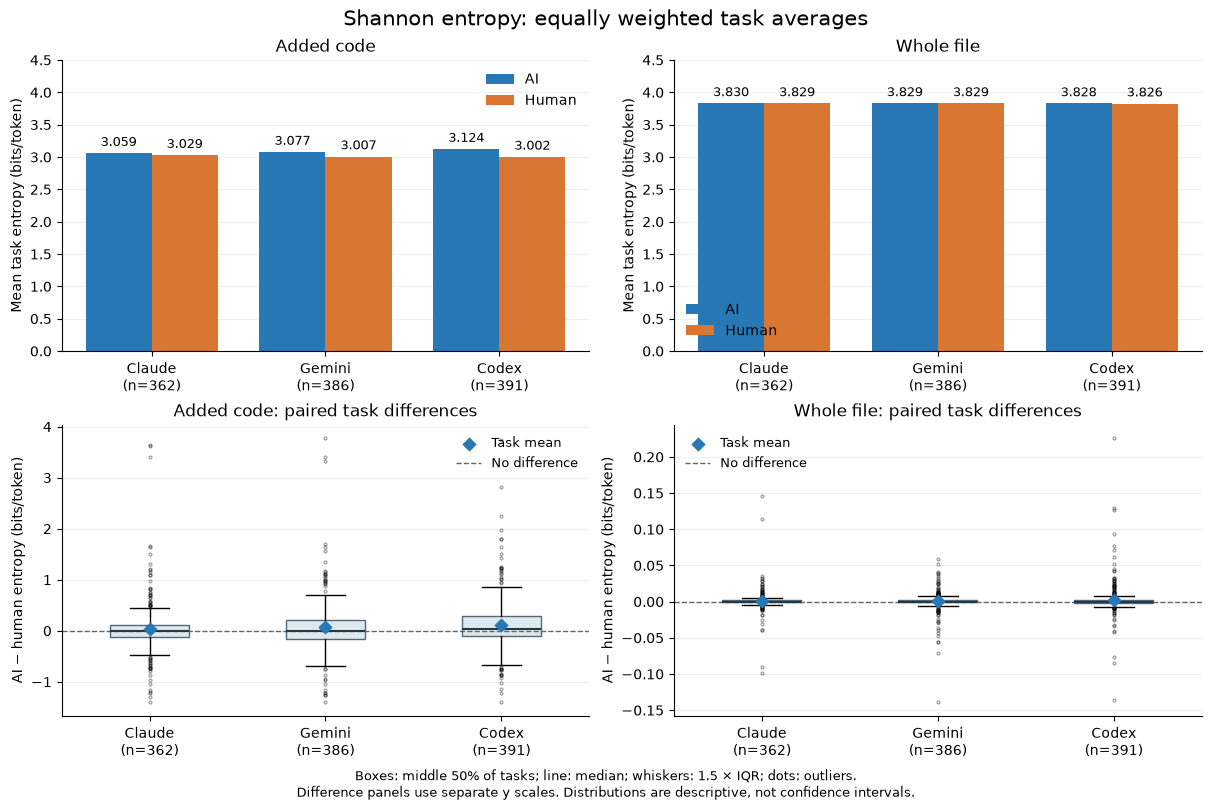

In [63]:
plot_entropy_distributions(entropy_tasks, MODELS)
plt.show()


### Entropy Direction Analysis

Analyze and visualize how often AI task entropy is higher or lower than human entropy.

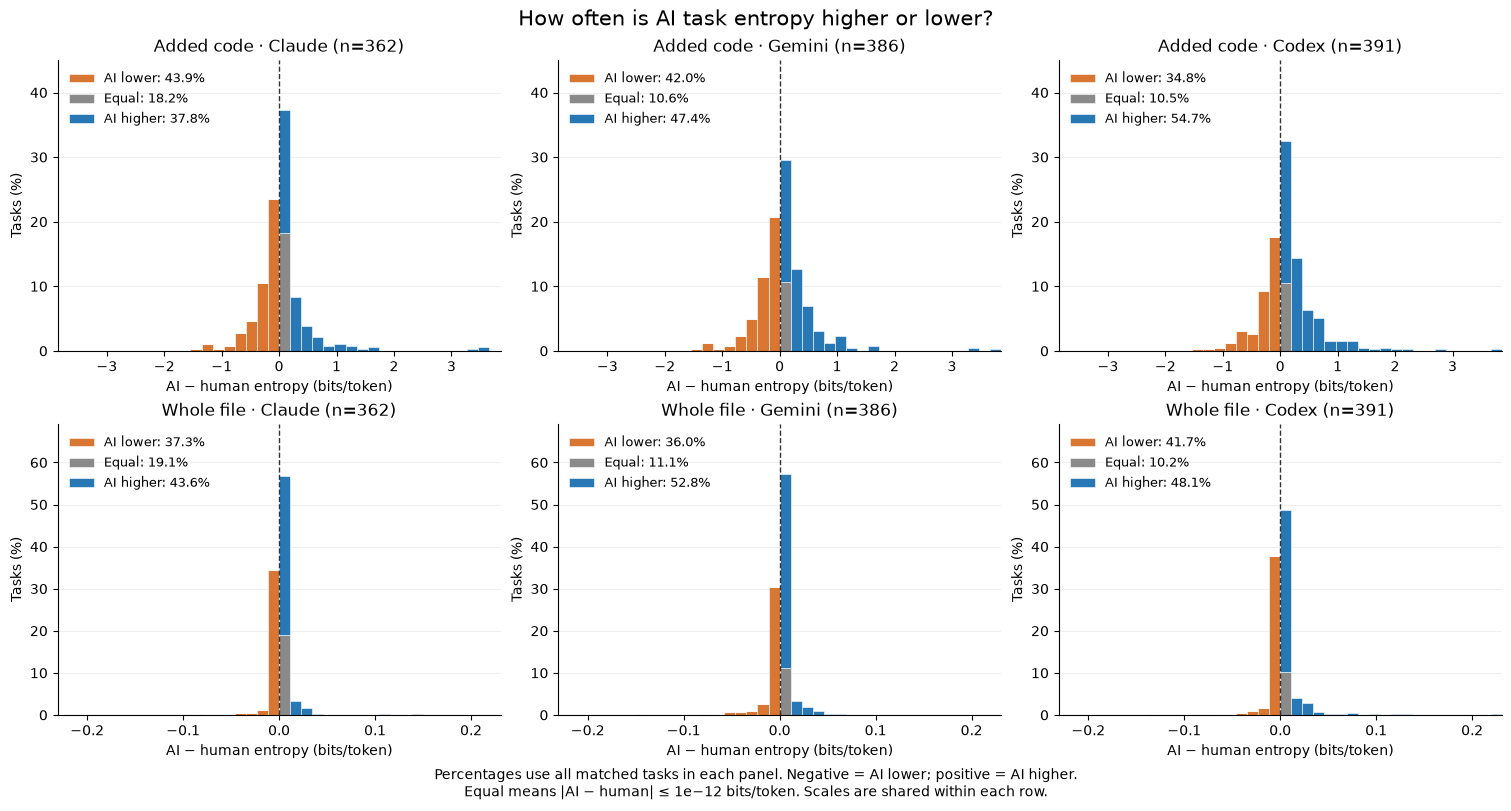

,Scope,Model,Tasks,AI lower (%),Equal (%),AI higher (%)
0,Added code,Claude,362,43.9,18.2,37.8
1,Added code,Gemini,386,42.0,10.6,47.4
2,Added code,Codex,391,34.8,10.5,54.7
3,Whole file,Claude,362,37.3,19.1,43.6
4,Whole file,Gemini,386,36.0,11.1,52.8
5,Whole file,Codex,391,41.7,10.2,48.1


In [64]:
entropy_direction_summary = summarize_entropy_direction(entropy_tasks, MODELS)
plot_entropy_direction_histograms(entropy_tasks, MODELS)
plt.show()

display(entropy_direction_summary.style.format({
    'AI lower (%)': '{:.1f}', 'Equal (%)': '{:.1f}', 'AI higher (%)': '{:.1f}',
}).set_caption('Percentage of paired tasks by entropy direction (AI relative to human).'))


## 3. Statistical analysis of Shannon entropy

For task $i$, average file entropies within each source, then compare the matched task means:

$$
\overline{H}_{i,s}=\frac{1}{F_i}\sum_{f=1}^{F_i}\widehat{H}_{i,s,f},
\qquad d_i=\overline{H}_{i,\mathrm{AI}}-\overline{H}_{i,\mathrm{human}},
\qquad T=\frac{1}{N}\sum_{i=1}^{N}d_i.
$$

**Hypothesis:** the task-mean difference is zero versus nonzero. Each task has equal weight. The two-sided paired sign-flip test below uses **19,999 permutations** and a plus-one Monte Carlo p-value; **19,999 task-paired bootstrap samples** give percentile 95% CIs (seed 503005). Holm correction covers three models *separately* for added- and whole-file analyses. Valid inference assumes exchangeable labels or symmetric differences under the null.

| Scope | Model | N | AI − human (bits) | 95% CI | Holm p (3) |
|---|---|---:|---:|---|---:|
| Added | Claude | 362 | +0.0306 | [−0.0193, 0.0833] | 0.2494 |
| Added | Gemini | 386 | +0.0699 | [0.0205, 0.1228] | **0.0113** |
| Added | Codex | 391 | +0.1214 | [0.0729, 0.1730] | **0.00015** |
| Whole | Claude | 362 | +0.00084 | [−0.00055, 0.00231] | 0.5349 |
| Whole | Gemini | 386 | +0.00036 | [−0.00101, 0.00160] | 0.6021 |
| Whole | Codex | 391 | +0.00262 | [0.00062, 0.00474] | **0.0297** |

**Interpretation.** Added-code entropy is higher for Gemini and Codex, but not distinguishably different for Claude. Whole-file effects are much smaller (only Codex significant). This suggests the differences are concentrated in changed code and are sensitive to representation and sampling; entropy does not measure token order.



Statistical inference:
Paired sign-flip permutation test with bootstrap confidence intervals.

References:
Ernst (2004), https://doi.org/10.1214/088342304000000396

SciPy: https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.permutation_test.html

Bootstrap: https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.bootstrap.html

Holm correction: https://www.statsmodels.org/dev/generated/statsmodels.stats.multitest.multipletests.html



### Definining the functions for the significance test


In [65]:

import numpy as np
import pandas as pd
from IPython.display import display

ENTROPY_RESAMPLES = 19_999
ENTROPY_SEED = 503005
ENTROPY_ALPHA = 0.05
BATCH_SIZE = 500

ENTROPY_SCOPES = {
    "added": "Added code",
    "whole": "Whole file",
}


def paired_entropy_test(
        task_pairs: pd.DataFrame,
        rng: np.random.Generator,
        repetitions: int = ENTROPY_RESAMPLES,
) -> dict:

    pairs = task_pairs[["ai_bits", "human_bits"]].to_numpy(dtype=float)

    if len(pairs) < 2 or not np.isfinite(pairs).all():
        raise ValueError("At least two finite matched task pairs are required")

    differences = pairs[:, 0] - pairs[:, 1]
    n_tasks = len(differences)
    observed = differences.mean()

    bootstrap_means = np.empty(repetitions)
    null_means = np.empty(repetitions)

    for start in range(0, repetitions, BATCH_SIZE):
        end = min(start + BATCH_SIZE, repetitions)
        batch_size = end - start

        indices = rng.integers(n_tasks, size=(batch_size, n_tasks))
        bootstrap_means[start:end] = differences[indices].mean(axis=1)

        signs = rng.integers(2, size=(batch_size, n_tasks)) * 2 - 1
        null_means[start:end] = (signs * differences).mean(axis=1)

    ci_low, ci_high = np.quantile(bootstrap_means, [0.025, 0.975])

    extreme = np.count_nonzero(
        np.abs(null_means) >= abs(observed) - 1e-14
    )
    p_value = (extreme + 1) / (repetitions + 1)

    return {
        "n_tasks": n_tasks,
        "difference_bits": observed,
        "ci_low": ci_low,
        "ci_high": ci_high,
        "p_two_sided": p_value,
    }


def holm_adjust(p_values) -> np.ndarray:

    p_values = np.asarray(p_values, dtype=float)
    order = np.argsort(p_values)

    adjusted = np.maximum.accumulate(
        p_values[order] * np.arange(len(p_values), 0, -1)
    )

    result = np.empty_like(p_values)
    result[order] = np.minimum(adjusted, 1.0)

    return result



### Running the statistical functions

In [66]:

def run_entropy_tests(entropy_tasks: pd.DataFrame, models: dict) -> pd.DataFrame:

    keys = ["model", "mode", "instance_id"]

    if entropy_tasks.duplicated(keys).any():
        raise ValueError("Expected one matched observation per model, scope and task")

    rng = np.random.default_rng(ENTROPY_SEED)
    results = []

    for scope in ENTROPY_SCOPES:
        scope_data = entropy_tasks[entropy_tasks["mode"] == scope]
        scope_results = []

        for model in models.values():
            task_pairs = (
                scope_data[scope_data["model"] == model["id"]]
                .sort_values("instance_id")
            )

            result = paired_entropy_test(task_pairs, rng)

            scope_results.append({
                "mode": scope,
                "model": model["id"],
                **result,
            })

        p_values = [result["p_two_sided"] for result in scope_results]
        adjusted_p_values = holm_adjust(p_values)

        for result, adjusted_p in zip(scope_results, adjusted_p_values):
            result["p_two_sided_holm"] = adjusted_p
            result["reject_holm_005"] = adjusted_p < ENTROPY_ALPHA

        results.extend(scope_results)

    return pd.DataFrame(results)


### Plotting the statistical functionsa

In [67]:

def display_entropy_results(results: pd.DataFrame, models: dict) -> None:

    model_names = {
        model["id"]: model["display"]
        for model in models.values()
    }

    summary = results.copy()

    summary["mode"] = summary["mode"].map(ENTROPY_SCOPES)
    summary["model"] = summary["model"].map(model_names)

    summary["95% CI (bits/token)"] = [
        f"[{low:+.5f}, {high:+.5f}]"
        for low, high in zip(summary["ci_low"], summary["ci_high"])
    ]

    summary = summary.rename(columns={
        "mode": "Scope",
        "model": "Model",
        "n_tasks": "Tasks",
        "difference_bits": "Mean AI − human (bits/token)",
        "p_two_sided": "Two-sided p",
        "p_two_sided_holm": "Holm p (3)",
        "reject_holm_005": "Significant (Holm < 0.05)",
    })

    columns = [
        "Scope",
        "Model",
        "Tasks",
        "Mean AI − human (bits/token)",
        "95% CI (bits/token)",
        "Two-sided p",
        "Holm p (3)",
        "Significant (Holm < 0.05)",
    ]

    styles = {
        "Mean AI − human (bits/token)": "{:+.5f}",
        "Two-sided p": "{:.5g}",
        "Holm p (3)": "{:.5g}",
        "Significant (Holm < 0.05)": lambda value: "Yes" if value else "No",
    }

    caption = (
        f"{ENTROPY_RESAMPLES:,} paired sign flips and task bootstrap samples; "
        f"seed {ENTROPY_SEED}. Holm correction is separate for each scope. "
        "Percentile 95% CIs are unadjusted."
    )

    display(
        summary[columns]
        .style
        .format(styles)
        .set_caption(caption)
    )


In [68]:

# The following cell runs statistical significance tests on the calculated task averages.
entropy_tests = run_entropy_tests(entropy_tasks, MODELS)
display_entropy_results(entropy_tests, MODELS)

,Scope,Model,Tasks,Mean AI − human (bits/token),95% CI (bits/token),Two-sided p,Holm p (3),Significant (Holm < 0.05)
0,Added code,Claude,362,+0.03061,"[-0.01926, +0.08332]",0.2494,0.2494,No
1,Added code,Gemini,386,+0.06986,"[+0.02046, +0.12275]",0.00565,0.0113,Yes
2,Added code,Codex,391,+0.12144,"[+0.07289, +0.17300]",5e-05,0.00015,Yes
3,Whole file,Claude,362,+0.00084,"[-0.00055, +0.00231]",0.26745,0.5349,No
4,Whole file,Gemini,386,+0.00036,"[-0.00101, +0.00160]",0.6021,0.6021,No
5,Whole file,Codex,391,+0.00262,"[+0.00062, +0.00474]",0.0099,0.0297,Yes


## Shannon Entropy: Results and Discussion

These results provide support for our H1, indicating that AI patches differ from human patches in token entropy.
For added code, Gemini (+0.070 bits/token, adjusted p = 0.0113) and Codex (+0.121 bits/token, adjusted p = 0.00015) exhibited significantly higher Shannon entropy than their human counterparts. Claude showed a smaller, non-significant difference (+0.031 bits/token, p = 0.2494). However, we do not see that same level of significance except for Codex. Entropy differences were substantially smaller which suggests that unchanged code may be diluting differences in entropy.

Limitations of this approach in answering H1 is that we are model dependent. Paired together with the small effect sizes—especially for whole files we can say that our approach supports H1 but is not conclusive of H1.

## 4. Mutual information

Lagged MI quantifies dependence between tokens $k$ positions apart:

$$
I_k=I(X_t;X_{t+k})=
\sum_{x,y}p_k(x,y)\log_2\!\frac{p_k(x,y)}{p_k(x)p_k(y)}.
$$

JIDT estimates MI from token pairs aggregated **within each task/source**, never across files. A length-$L$ file contributes $\max(L-k,0)$ pairs; no available pairs means MI is undefined, not zero.

**Excess MI** subtracts the mean of **200 within-file token-order shuffles**, preserving each file's length and token frequencies:

$$
I^{\mathrm{ex}}_{i,s}(k)=\widehat I_{i,s}(k)
-\frac{1}{200}\sum_{r=1}^{200}\widehat I^{\mathrm{shuffle},r}_{i,s}(k).
$$

Negative values are retained. The shuffle reference helps diagnose finite-sample inflation but is **not an unbiased correction** and differs from JIDT's pooled independence-test null. Results describe distance in *compressed added-code tokens*, not necessarily in continuous source code. Patch lengths, vocabulary and changing lag eligibility remain potential influences.

In [69]:
# TODO: Load per-task raw and shuffled-baseline MI; calculate excess MI and decay curves.


## 5. Statistical analysis of mutual information

**Question:** does excess MI differ between AI and human patches? Within-source JIDT independence tests answer a *different* question (whether each source has token dependence).

For each lag window $W$, include only tasks valid at every lag on both sides and compute:

$$
D_{i,W}=\frac{1}{|W|}\sum_{k\in W}
\left[I^{\mathrm{ex}}_{i,\mathrm{AI}}(k)-I^{\mathrm{ex}}_{i,\mathrm{human}}(k)\right],
\qquad T_W=\frac{1}{N_W}\sum_{i=1}^{N_W}D_{i,W}.
$$

Use **9,999 two-sided paired sign flips**, one per task, and **9,999 paired bootstrap replicates** for 95% percentile CIs (seeds 503020/503021). The two-sided Monte Carlo p-value is

$$
p=\frac{1+\#\{b:\lvert T_b\rvert\geq\lvert T_{\mathrm{obs}}\rvert\}}{B+1}.
$$

### Short-range results: original three-model family

| Model | N | Difference (bits) | 95% CI | Raw p | Holm p (3) |
|---|---:|---:|---|---:|---:|
| Claude | 239 | +0.01435 | [−0.00674, 0.03531] | 0.1823 | 0.1823 |
| Gemini | 254 | +0.03522 | [0.01387, 0.05699] | 0.0012 | **0.0036** |
| Codex | 260 | +0.02314 | [0.00336, 0.04285] | 0.0211 | **0.0422** |

These are the original **lags 1–20** results. Gemini and Codex are significant within this three-test family. However, the window was chosen after inspecting preliminary curves, so results remain exploratory.

### Extended lag windows: nine-test family

| Model | Lags | N | Difference (bits) | 95% CI | Holm p (9) |
|---|---|---:|---:|---|---:|
| Claude | 1–20 | 239 | +0.01435 | [−0.00674, 0.03531] | 0.5469 |
| Claude | 21–40 | 109 | +0.04388 | [0.00709, 0.08179] | 0.1688 |
| Claude | 41–60 | 75 | +0.03673 | [−0.00131, 0.07862] | 0.4458 |
| Gemini | 1–20 | 254 | +0.03522 | [0.01387, 0.05699] | **0.0108** |
| Gemini | 21–40 | 128 | +0.02928 | [−0.00376, 0.06202] | 0.4458 |
| Gemini | 41–60 | 81 | +0.00498 | [−0.03763, 0.04997] | 0.8328 |
| Codex | 1–20 | 260 | +0.02314 | [0.00336, 0.04285] | 0.1688 |
| Codex | 21–40 | 128 | +0.02533 | [−0.00379, 0.05557] | 0.4458 |
| Codex | 41–60 | 83 | −0.02128 | [−0.05458, 0.00937] | 0.5469 |

**Only Gemini at lags 1–20 survives Holm correction across all nine tests.** The original effect estimates and raw p-values did not change; the correction family expanded. Pointwise CIs are not multiplicity-adjusted.

**Does the difference decay?** On fixed cohorts valid over all lags 1–60, Gemini's estimates decrease (+0.0423, +0.0299, +0.0050; $N=81$); Codex falls through zero (+0.0354, +0.0211, −0.0213; $N=83$); Claude is nonmonotonic (+0.0432, +0.0490, +0.0367; $N=75$). These are **descriptive**, not tested between-window contrasts. Changing eligibility across windows also complicates comparisons.

**Full-profile test.** A secondary sum-of-squared-mean-differences permutation test over lags 1–100 finds no significant profile differences: Claude $p=0.0515$ ($N=36$), Gemini $p=0.0919$ ($N=41$), Codex $p=0.1185$ ($N=43$); these global p-values are unadjusted. Small complete-case cohorts limit power; failure to reject is not equivalence.

**Length sensitivity.** Prefix-length matching reduced original 1–20 differences to −0.0020, +0.0037 and +0.0054 bits (Claude/Gemini/Codex; each Holm $p=1$). Thus the significant short-range findings were **not robust** to this procedure. Truncation changes both length *and content*, so length alone is not a proven cause. Lag-specific tests also exist (Holm within each model across 100 lags) but do not change these conclusions.

In [70]:
# TODO: Reproduce paired MI tests, corrections, confidence intervals, and window comparisons.


## 6. Active information storage

AIS measures how much a token's preceding $h$-token history tells us about the next token:

$$
A_h=I\!\left((X_{t-h},\ldots,X_{t-1});X_t\right).
$$

Unlike lagged MI, AIS uses a **joint history**. AIS at $h=1$ corresponds to lag-one MI only when observations and estimators match; it is not independent corroboration.

**Measurement.** Sample 20 **50-token windows** per source/task within contiguous added-code blocks (no unchanged gaps), then average within task. Each window has 50 shuffled-token controls; *excess AIS* is observed minus mean shuffled AIS, retaining negative values. The primary history lengths are **$h=2$ and $h=3$** (48 and 47 usable history–target observations per window). The discrete history-state estimator is checked against JIDT; sampling is reproducible (configuration seed 503003).

**Key limitation: sparse histories.** Possible histories grow rapidly with $h$. Median singleton-history fractions in the primary cohort are about 0.107, 0.326 and 0.535 for $h=1,2,3$. A unique observed history can make in-sample prediction appear perfect without generalizing. Shuffled controls help diagnose, but cannot eliminate, finite-sample bias. Extended histories use different windows/cohorts and are not directly comparable.

In [71]:
# TODO: Load or calculate task-level active information storage and sparsity diagnostics.


## 7. Statistical analysis of active information storage

For each history length, average window-level excess AIS within source/task and test the mean matched **AI − human** difference. Unlike entropy and MI, the saved AIS primary test is **one-sided** ($H_1$: AI excess AIS is greater). It uses **19,999 paired sign flips** and **19,999 paired bootstrap samples** (inference seed 503103). Holm correction covers **six tests**: two histories ($h=2,3$) across three models. The 95% CIs are two-sided, unadjusted percentile intervals.

| Model | History $h$ | N | Difference (bits) | 95% CI | One-sided Holm p (6) |
|---|---:|---:|---:|---|---:|
| Claude | 2 | 57 | +0.02409 | [0.00225, 0.04576] | 0.0700 |
| Claude | 3 | 57 | +0.00023 | [−0.01617, 0.01593] | 0.9752 |
| Gemini | 2 | 54 | +0.02410 | [−0.00512, 0.05314] | 0.1677 |
| Gemini | 3 | 54 | −0.00401 | [−0.02661, 0.01861] | 0.9752 |
| Codex | 2 | 66 | +0.03608 | [0.01218, 0.06005] | **0.0111** |
| Codex | 3 | 66 | +0.02006 | [0.00301, 0.03731] | 0.0700 |

**Finding.** Only Codex at $h=2$ is significant after six-test correction. Yet its estimate changes from +0.0361 to approximately −0.0225 bits with coarse token encoding; its 100-token-window sensitivity has adjusted $p=1$. This weakens any claim of a robust authorship signature.

**Additional checks.** Repository-cluster analyses recognize that tasks from the same project may be dependent, but the primary cohorts span only 9–10 repositories. The separate 1–20- and 1–100-history sweeps (Holm across 60 and 300 comparisons) find no significant primary-cohort excess-AIS effects. The latter uses 130-token windows and only 5–8 eligible tasks per model. Long histories suffer severe state sparsity; these sweeps do not replicate the primary six-test design.

In [72]:
# TODO: Reproduce paired AIS inference and summarize existing sensitivity results.


## 8. Discussion and conclusions

| Measure | Main result | Interpretation |
|---|---|---|
| **Shannon entropy** | Added-code entropy is higher for Gemini and Codex (Holm-adjusted $p=0.0113$ and $0.00015$). | Changes in **token-frequency diversity**; whole-file differences are much smaller. |
| **Mutual information** | Gemini and Codex differ at lags 1–20 in the original three-test family; only Gemini survives correction across nine lag-window tests ($p=0.0108$). | Dependence differences are **small, window- and cohort-sensitive**, and disappear under prefix-length matching. |
| **Active information storage** | Codex has higher excess AIS at history two (one-sided Holm $p=0.0111$). | A narrowly specified effect that changes with encoding and window length. |

### Interpretation and critical evaluation

The three measures address different mechanisms: entropy ignores order, lagged MI captures pairwise token dependence, and AIS captures dependence on a joint history. Their different results suggest **no universal, robust information-theoretic signature of AI authorship** in this selected dataset. They also explain why a detectable group difference is not automatically a useful patch-level classifier.

Crucial limits are **observational agent/model provenance**, repository-level dependence, selection of reconstructed Python additions, unequal patch lengths, finite-sample estimator bias and sparse AIS histories. MI may bridge omitted gaps; AIS does not. Some results survive their stated multiple-testing correction but not alternative representations or sampling. A nonsignificant result does **not** establish equivalence. Comparing classification accuracy would require held-out tasks and a separate predictive experiment.

### Reproducibility and related work

Shannon entropy measurements and paired inference are recomputed above from raw data using JIDT and NumPy. MI and AIS results are transcribed from saved analyses. Main sources: `experiments/hypothesis-1/results/hybrid-encoding/paired_tests.csv` (entropy); `experiments/hypothesis-2-mi/results/paired-significance/` (MI, windows and sensitivity); and `experiments/hypothesis-2-ais/results/` (AIS). The MI and AIS code cells remain placeholders.

Foundational references: Shannon (1948), *A Mathematical Theory of Communication*; Lizier (2014), *JIDT: An Information-Theoretic Toolkit for Studying the Dynamics of Complex Systems*; Jimenez et al. (2024), *SWE-bench: Can Language Models Resolve Real-World GitHub Issues?*. These provide the information-theoretic framework, estimator toolkit and matched issue-resolution dataset; this study tests **interpretable information measures rather than building an authorship classifier**.

In [73]:
# TODO: Generate final result tables and figures from the analyses above.


## 7. Statistical analysis of active information storage

For each history length, average window-level excess AIS within source/task and test the mean matched **AI − human** difference. Unlike entropy and MI, the saved AIS primary test is **one-sided** ($H_1$: AI excess AIS is greater). It uses **19,999 paired sign flips** and **19,999 paired bootstrap samples** (inference seed 503103). Holm correction covers **six tests**: two histories ($h=2,3$) across three models. The 95% CIs are two-sided, unadjusted percentile intervals.

| Model | History $h$ | N | Difference (bits) | 95% CI | One-sided Holm p (6) |
|---|---:|---:|---:|---|---:|
| Claude | 2 | 57 | +0.02409 | [0.00225, 0.04576] | 0.0700 |
| Claude | 3 | 57 | +0.00023 | [−0.01617, 0.01593] | 0.9752 |
| Gemini | 2 | 54 | +0.02410 | [−0.00512, 0.05314] | 0.1677 |
| Gemini | 3 | 54 | −0.00401 | [−0.02661, 0.01861] | 0.9752 |
| Codex | 2 | 66 | +0.03608 | [0.01218, 0.06005] | **0.0111** |
| Codex | 3 | 66 | +0.02006 | [0.00301, 0.03731] | 0.0700 |

**Finding.** Only Codex at $h=2$ is significant after six-test correction. Yet its estimate changes from +0.0361 to approximately −0.0225 bits with coarse token encoding; its 100-token-window sensitivity has adjusted $p=1$. This weakens any claim of a robust authorship signature.

**Additional checks.** Repository-cluster analyses recognize that tasks from the same project may be dependent, but the primary cohorts span only 9–10 repositories. The separate 1–20- and 1–100-history sweeps (Holm across 60 and 300 comparisons) find no significant primary-cohort excess-AIS effects. The latter uses 130-token windows and only 5–8 eligible tasks per model. Long histories suffer severe state sparsity; these sweeps do not replicate the primary six-test design.

In [74]:
# TODO: Reproduce paired AIS inference and summarize existing sensitivity results.


## 8. Discussion and conclusions

| Measure | Main result | Interpretation |
|---|---|---|
| **Shannon entropy** | Added-code entropy is higher for Gemini and Codex (Holm-adjusted $p=0.0113$ and $0.00015$). | Changes in **token-frequency diversity**; whole-file differences are much smaller. |
| **Mutual information** | Gemini and Codex differ at lags 1–20 in the original three-test family; only Gemini survives correction across nine lag-window tests ($p=0.0108$). | Dependence differences are **small, window- and cohort-sensitive**, and disappear under prefix-length matching. |
| **Active information storage** | Codex has higher excess AIS at history two (one-sided Holm $p=0.0111$). | A narrowly specified effect that changes with encoding and window length. |

### Interpretation and critical evaluation

The three measures address different mechanisms: entropy ignores order, lagged MI captures pairwise token dependence, and AIS captures dependence on a joint history. Their different results suggest **no universal, robust information-theoretic signature of AI authorship** in this selected dataset. They also explain why a detectable group difference is not automatically a useful patch-level classifier.

Crucial limits are **observational agent/model provenance**, repository-level dependence, selection of reconstructed Python additions, unequal patch lengths, finite-sample estimator bias and sparse AIS histories. MI may bridge omitted gaps; AIS does not. Some results survive their stated multiple-testing correction but not alternative representations or sampling. A nonsignificant result does **not** establish equivalence. Comparing classification accuracy would require held-out tasks and a separate predictive experiment.

### Reproducibility and related work

Shannon entropy measurements and paired inference are recomputed above from raw data using JIDT and NumPy. MI and AIS results are transcribed from saved analyses. Main sources: `experiments/hypothesis-1/results/hybrid-encoding/paired_tests.csv` (entropy); `experiments/hypothesis-2-mi/results/paired-significance/` (MI, windows and sensitivity); and `experiments/hypothesis-2-ais/results/` (AIS). The MI and AIS code cells remain placeholders.

Foundational references: Shannon (1948), *A Mathematical Theory of Communication*; Lizier (2014), *JIDT: An Information-Theoretic Toolkit for Studying the Dynamics of Complex Systems*; Jimenez et al. (2024), *SWE-bench: Can Language Models Resolve Real-World GitHub Issues?*. These provide the information-theoretic framework, estimator toolkit and matched issue-resolution dataset; this study tests **interpretable information measures rather than building an authorship classifier**.

In [75]:
# TODO: Generate final result tables and figures from the analyses above.
